## 1. Imports and shared code

In [1]:
import sys
import time
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

sys.path.insert(0, str(Path("../../src").resolve()))
from recplay.windowed import (rqa_frame, rrc_frame, window_surrogates, euclidean_distance,
                              exp_euclidean_distance, beta_distance)

## 2. Data

In [2]:
# Load FRED monthly series
DATA_DIR = Path("../../data/raw/fred")  # relative to notebooks/02_macro/, where this notebook lives

def load_csv(name: str) -> pd.Series:
    df = pd.read_csv(DATA_DIR / f"{name}.csv", parse_dates=["observation_date"], index_col="observation_date")
    return df[name].astype(float)

cpi = load_csv("CPIAUCSL")
unrate = load_csv("UNRATE")
fedfunds = load_csv("FEDFUNDS")

for s in (cpi, unrate, fedfunds):
    print(f"{s.name:9s} {s.index.min().date()} to {s.index.max().date()}  n={len(s)}  missing={s.isna().sum()}")

CPIAUCSL  1947-01-01 to 2026-09-01  n=957  missing=1
UNRATE    1948-01-01 to 2026-09-01  n=945  missing=1
FEDFUNDS  1954-07-01 to 2026-09-01  n=867  missing=0


In [3]:
# Impute October 2025 as Bureau of labor stats did not collect CPI or household-survey data during the shutdown

cpi_m, unrate_m, fedfunds_m = (s.asfreq("MS") for s in (cpi, unrate, fedfunds))

cpi_imputed = cpi_m.isna()
unrate_imputed = unrate_m.isna()

print("Imputing CPI at:", list(cpi_m.index[cpi_imputed].date))
print("Imputing UNRATE at:", list(unrate_m.index[unrate_imputed].date))
assert not fedfunds_m.isna().any()

cpi_clean = np.exp(np.log(cpi_m).interpolate(method="linear", limit_area="inside"))  # geometric for a price level
unrate_clean = unrate_m.interpolate(method="linear", limit_area="inside")
fedfunds_clean = fedfunds_m

print(pd.DataFrame({"CPIAUCSL": cpi_clean, "UNRATE": unrate_clean}).loc["2025-09":"2025-11"])

Imputing CPI at: [datetime.date(2025, 10, 1)]
Imputing UNRATE at: [datetime.date(2025, 10, 1)]


,CPIAUCSL,UNRATE
observation_date,,
2025-09-01,324.245000,4.40
2025-10-01,324.653742,4.45
2025-11-01,325.063000,4.50


In [4]:
# CPI level turned to YoY inflation, on the full CPI history (1947-), thus no lost months at the 1954 start
# YoY inflation instead of MoM inflation, avoiding overly noisy periods 
inflation = (100 * (np.log(cpi_clean) - np.log(cpi_clean.shift(12)))).rename("INFLATION")

# A YoY value is imputed if either of its two CPI inputs was imputed
inflation_imputed = cpi_imputed | cpi_imputed.shift(12, fill_value=False)

inflation = inflation.dropna()
inflation_imputed = inflation_imputed.loc[inflation.index]
print(f"INFLATION {inflation.index.min().date()} to {inflation.index.max().date()}  n={len(inflation)}")

INFLATION 1948-01-01 to 2026-09-01  n=945


In [5]:
# Common window, checks
macro = pd.concat([inflation, unrate_clean, fedfunds_clean], axis=1, join="inner")
macro["IMPUTED"] = (inflation_imputed | unrate_imputed).loc[macro.index]

assert macro.index.is_monotonic_increasing and macro.index.is_unique
assert len(macro.asfreq("MS")) == len(macro), "gap in monthly index"
assert not macro.isna().any().any(), "NaN left after cleaning"

print(f"{macro.index.min().date()} to {macro.index.max().date()}  n={len(macro)}")
print("Imputed rows:", list(macro.index[macro["IMPUTED"]].date))
macro.head()

1954-07-01 to 2026-09-01  n=867
Imputed rows: [datetime.date(2025, 10, 1)]


,INFLATION,UNRATE,FEDFUNDS,IMPUTED
observation_date,,,,
1954-07-01,0.260951,5.8,0.80,False
1954-08-01,0.000000,6.0,1.22,False
1954-09-01,-0.297952,6.1,1.07,False
1954-10-01,-0.857095,5.7,0.85,False
1954-11-01,-0.261048,5.3,0.83,False


In [6]:
# Monthly inflation on the full CPI history, so its lags are complete from 1954-07; YoY is exactly its 12-month sum
pi = (100 * np.log(cpi_clean).diff()).rename("PI")
macro["PI"] = pi.loc[macro.index]
assert np.allclose(pi.rolling(12).sum().loc[macro.index], macro.INFLATION)

## 3. Targets and evaluation calendar

In [7]:
HORIZONS = [1, 3, 6, 12]
SCREEN_YEARS = (1975, 1999)
FINAL_YEARS = (2000, 2026)
yoy = macro.INFLATION

# Row t is 1 if YoY h months later is strictly higher than at t
targets = {h: (yoy.shift(-h) > yoy).astype(int)[yoy.shift(-h).notna()] for h in HORIZONS}
label_imputed = {h: (macro.IMPUTED | macro.IMPUTED.shift(-h, fill_value=False)).loc[targets[h].index] for h in HORIZONS}


def blocks(h, first_year, last_year):
    """The model for year Y is fitted at the start of Y, on rows whose h-month label is known by then."""
    idx = targets[h].index
    for year in range(first_year, last_year + 1):
        start = pd.Timestamp(year, 1, 1)
        train = idx.shift(h, freq="MS") <= start
        test = idx.year == year
        if not test.any():
            continue
        assert idx[train].max() + pd.DateOffset(months=h) <= start <= idx[test].min()
        yield train, test


def scored_rows(h, first_year, last_year):
    test = np.zeros(len(targets[h]), bool)
    for _, t in blocks(h, first_year, last_year):
        test |= t
    return test & ~label_imputed[h].to_numpy()


def make_classifier():
    return LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, num_leaves=7, min_child_samples=20,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=0, n_jobs=1, verbose=-1)


def evaluate(X, h, first_year, last_year):
    y = targets[h]
    has = y.index.isin(X.index)
    X = X.reindex(y.index)
    pred = pd.Series(np.nan, index=y.index)
    for train, test in blocks(h, first_year, last_year):
        train &= has
        assert has[test].all()
        model = make_classifier().fit(X[train], y[train])
        pred[test] = model.predict_proba(X[test])[:, 1]
    rows = scored_rows(h, first_year, last_year)
    p, t = pred[rows], y[rows]
    return {"auc": roc_auc_score(t, p), "acc": accuracy_score(t, p >= 0.5), "n_test": int(rows.sum())}, p


def auc_gain(p_new, p_base, labels, n=2000):
    """AUC(p_new) - AUC(p_base) on the same months, with a 95% interval from resampling whole calendar years."""
    t = labels[p_new.index]
    years = p_new.index.year
    groups = [np.flatnonzero(years == yr) for yr in np.unique(years)]
    rng = np.random.default_rng(0)
    diffs = []
    for _ in range(n):
        i = np.concatenate([groups[g] for g in rng.integers(0, len(groups), len(groups))])
        diffs.append(roc_auc_score(t.iloc[i], p_new.iloc[i]) - roc_auc_score(t.iloc[i], p_base.iloc[i]))
    return roc_auc_score(t, p_new) - roc_auc_score(t, p_base), *np.quantile(diffs, [0.025, 0.975])


print(pd.DataFrame({h: {"screening rows": scored_rows(h, *SCREEN_YEARS).sum(),
                        "final rows": scored_rows(h, *FINAL_YEARS).sum()} for h in HORIZONS}))

,1,3,6,12
screening rows,300,300,300,300
final rows,318,316,313,308


## 4. Lag and base-effect features

In [8]:
def lagged_values(data=macro):
    dpi = data.INFLATION.diff()
    return pd.concat({f"dpi_lag{k}": dpi.shift(k) for k in range(12)}, axis=1).join(data[["INFLATION", "UNRATE", "FEDFUNDS"]])


def base_effect(h, pi=pi):
    """π_{t-11} + ... + π_{t-12+h}: the monthly inflation that leaves the YoY sum over the next h months."""
    return pi.rolling(h).sum().shift(12 - h)


def lags_base(h, data=macro, pi=pi):
    pi_lags = pd.concat({f"pi_lag{k}": pi.shift(k) for k in range(13)}, axis=1)
    return lagged_values(data).join(pi_lags).join(base_effect(h, pi).rename("base_effect"))


# YoY(t+h) - YoY(t) = (π_{t+1} + ... + π_{t+h}) - base effect, so only the first sum is unknown at t
for h in HORIZONS:
    gap = (yoy.shift(-h) - yoy) - (pi.rolling(h).sum().shift(-h) - base_effect(h)).loc[macro.index]
    assert gap.abs().max() < 1e-9

lag_base_features = {h: lags_base(h) for h in HORIZONS}

## 5. Window features

Delete `data/processed/beta_refinement/` after changing feature code.

In [9]:
CACHE_DIR = Path("../../data/processed/beta_refinement")
SURR_DIR = CACHE_DIR / "iaaft"
SERIES = {"pi": "PI"}
W, M, TAU, RR = 120, 2, 1, 0.05
RQA_KEEP = ["DET", "L", "ENTR", "LAM", "DET3_DET2", "K2_lines", "RR_last"]
THEILER, RRC_DELTA, N_SURR = 1, 0.05, 19
WINDOW_COLS = [f"pi_{k}" for k in RQA_KEEP] + ["pi_RRc", "pi_dRRc", "pi_mean", "pi_std"]
INITIAL_BETAS = [-5.0, -2.0, -1.0, -0.5, 0.5, 1.0, 2.0, 5.0]
REFERENCE_ARMS = ["euclid_z", "euclid_expz"]


def arm_key(arm):
    return arm if isinstance(arm, str) else float(f"{arm:.10g}")


def arm_name(arm):
    return arm if isinstance(arm, str) else f"b{arm:.10g}"


def distance_for(arm):
    if arm == "euclid_z":
        return euclidean_distance
    if arm == "euclid_expz":
        return exp_euclidean_distance
    return partial(beta_distance, beta=arm)


def rp_features(arm, data=macro) -> pd.DataFrame:
    df = rqa_frame(data, SERIES, {}, W, M, TAU, RR, distance_for(arm), THEILER)
    # ε comes from the target rate, so the RR of the whole window carries no information
    assert df["pi_RR"].std() < 1e-3
    return df


def rrc_features(arm, data=macro, surrogates=None) -> pd.DataFrame:
    if surrogates is None:
        surrogates = window_surrogates(data, SERIES, W, N_SURR)
    return rrc_frame(data, SERIES, {}, W, M, TAU, distance_for(arm), surrogates, THEILER, RRC_DELTA)


def moments(W, data=macro) -> pd.DataFrame:
    """Mean and std of the raw window; the RP itself only sees the z-scored window."""
    x = data.PI.rolling(W)
    return pd.DataFrame({"pi_mean": x.mean(), "pi_std": x.std(ddof=0)}).iloc[W - 1 :]


def cached(path, build, load=True):
    if path.exists():
        return pd.read_pickle(path) if load else None
    path.parent.mkdir(parents=True, exist_ok=True)
    obj = build()
    tmp = path.with_suffix(".tmp")
    pd.to_pickle(obj, tmp)
    tmp.replace(path)
    return obj if load else None


def load_surrogates(W, load=True):
    return cached(SURR_DIR / f"W{W}_n{N_SURR}.pkl", lambda: window_surrogates(macro, SERIES, W, N_SURR), load)


def arm_paths(arm):
    return CACHE_DIR / "rqa" / f"{arm_name(arm)}.pkl", CACHE_DIR / "rrc" / f"{arm_name(arm)}.pkl"


def load_arm(arm, load=True):
    rqa_path, rrc_path = arm_paths(arm)
    rqa_df = cached(rqa_path, lambda: rp_features(arm), load)
    rrc_df = cached(rrc_path, lambda: rrc_features(arm, surrogates=load_surrogates(W)), load)
    return rqa_df.join(rrc_df).join(moments(W))[WINDOW_COLS] if load else None


def build_arms(arms):
    arms = [arm_key(a) for a in arms]
    load_surrogates(W, load=False)
    todo = [a for a in arms if not all(p.exists() for p in arm_paths(a))]
    # Each arm writes only its own files, so parallel jobs never collide
    Parallel(n_jobs=-1)(delayed(load_arm)(a, load=False) for a in todo)
    return {a: load_arm(a) for a in arms}


window_features = {}

In [10]:
PROFILE_MEASURES = [f"pi_{k}" for k in RQA_KEEP] + ["pi_RRc", "pi_dRRc"]


def beta_profile(features) -> pd.DataFrame:
    """Per month and measure, a quadratic in x = β/5 over the 8 initial β: level c0, slope c1, curvature c2."""
    x = np.array(INITIAL_BETAS) / 5
    idx = features[arm_key(INITIAL_BETAS[0])].index
    cols = {}
    for meas in PROFILE_MEASURES:
        V = np.column_stack([features[arm_key(b)][meas].reindex(idx).to_numpy() for b in INITIAL_BETAS])
        coef = np.full((len(V), 3), np.nan)
        finite = np.isfinite(V)
        for pattern in np.unique(finite, axis=0):
            if pattern.sum() < 3:
                continue
            rows = (finite == pattern).all(axis=1)
            coef[rows] = np.polyfit(x[pattern], V[rows][:, pattern].T, 2).T
        cols[f"{meas}_curv"], cols[f"{meas}_slope"], cols[f"{meas}_level"] = coef.T
    order = [f"{m}_{k}" for m in PROFILE_MEASURES for k in ("level", "slope", "curv")]
    return pd.DataFrame(cols, index=idx)[order].join(moments(W))

In [11]:
t0 = time.perf_counter()
window_features.update(build_arms(REFERENCE_ARMS + INITIAL_BETAS))
profile_features = beta_profile(window_features)
print(f"{len(window_features)} arms in {time.perf_counter() - t0:.0f} s; profile features {profile_features.shape}")

10 arms in 52 s; profile features (748, 29)


## 6. Checks

In [12]:
for arm in ["euclid_expz", -2.0]:
    for month in ["1980-06-01", "1995-01-01", "2020-04-01"]:
        # Only the last window plus one month: the row for `month` must not need anything else
        sub = macro.loc[:month].iloc[-(W + 1):]
        trunc = rp_features(arm, sub).join(rrc_features(arm, sub)).join(moments(W, sub))[WINDOW_COLS]
        assert np.allclose(window_features[arm].loc[month], trunc.loc[month], equal_nan=True), (arm, month)

# β = 2 is half the squared Euclidean distance of exp(z) states, so the RPs at a fixed rate are identical
assert np.allclose(window_features[2.0], window_features["euclid_expz"], equal_nan=True)
print("leakage check passed; β = 2 matches Euclidean on exp(z)")

leakage check passed; β = 2 matches Euclidean on exp(z)


## 7. Depth 1

In [13]:
REFERENCE_MODELS = ["lags+base", "euclid_z", "euclid_expz", "beta_profile"]
PERIODS = {"screen": SCREEN_YEARS, "final": FINAL_YEARS}
results = {}


def feature_matrix(arm, h):
    if arm == "lags+base":
        return lag_base_features[h]
    if arm == "beta_profile":
        return lag_base_features[h].join(profile_features)
    return lag_base_features[h].join(window_features[arm])


def fit_all(arms, period, horizons=HORIZONS):
    jobs = [(a, h) for a in arms for h in horizons if (period, a, h) not in results]
    out = Parallel(n_jobs=-1)(delayed(evaluate)(feature_matrix(a, h), h, *PERIODS[period]) for a, h in jobs)
    results.update({(period, a, h): r for (a, h), r in zip(jobs, out)})

In [14]:
t0 = time.perf_counter()
fit_all(REFERENCE_MODELS + INITIAL_BETAS, "screen")
assert all(results["screen", a, h][0]["n_test"] == 300 for a in REFERENCE_MODELS + INITIAL_BETAS for h in HORIZONS)
tried = {h: {b: 1 for b in INITIAL_BETAS} for h in HORIZONS}
print(f"depth 1: {len(results)} models in {time.perf_counter() - t0:.0f} s")

depth 1: 48 models in 10 s


## 8. Refinement

In [15]:
def next_betas(auc: dict[float, float]) -> list[float]:
    """8 evenly spaced β strictly between the best tried β and its better neighbour."""
    betas = sorted(auc)
    i = max(range(len(betas)), key=lambda k: (auc[betas[k]], -betas[k]))
    neighbours = [betas[k] for k in (i - 1, i + 1) if 0 <= k < len(betas)]
    neighbour = max(neighbours, key=lambda b: (auc[b], -b))
    lo, hi = sorted((betas[i], neighbour))
    return [b for b in (arm_key(lo + (hi - lo) * k / 9) for k in range(1, 9)) if abs(b) >= 1e-9]

In [16]:
t0 = time.perf_counter()
for depth in (2, 3):
    new = {h: next_betas({b: results["screen", b, h][0]["auc"] for b in tried[h]}) for h in HORIZONS}
    window_features.update(build_arms(sorted({b for bs in new.values() for b in bs} - window_features.keys())))
    for h in HORIZONS:
        fit_all(new[h], "screen", horizons=[h])
        tried[h].update({b: depth for b in new[h]})
        best = max(tried[h], key=lambda b: (results["screen", b, h][0]["auc"], -b))
        print(f"depth {depth}, h = {h:2d}: searched ({min(new[h]):.4g}, {max(new[h]):.4g}), "
              f"best β so far {best:.4g} (AUC {results['screen', best, h][0]['auc']:.4f})")
print(f"refinement in {time.perf_counter() - t0:.0f} s")

depth 2, h =  1: searched (-0.3889, 0.3889), best β so far -0.1667 (AUC 0.8117)
depth 2, h =  3: searched (-0.9444, -0.5556), best β so far -0.7222 (AUC 0.8090)
depth 2, h =  6: searched (-0.3889, 0.3889), best β so far 0.2778 (AUC 0.7528)
depth 2, h = 12: searched (-0.3889, 0.3889), best β so far -0.2778 (AUC 0.6606)
depth 3, h =  1: searched (-0.2654, -0.179), best β so far -0.1667 (AUC 0.8117)
depth 3, h =  3: searched (-0.7716, -0.7284), best β so far -0.7469 (AUC 0.8202)
depth 3, h =  6: searched (0.2901, 0.3765), best β so far 0.3272 (AUC 0.7573)
depth 3, h = 12: searched (-0.2654, -0.179), best β so far -0.179 (AUC 0.6845)
refinement in 149 s


## 9. Screening curves

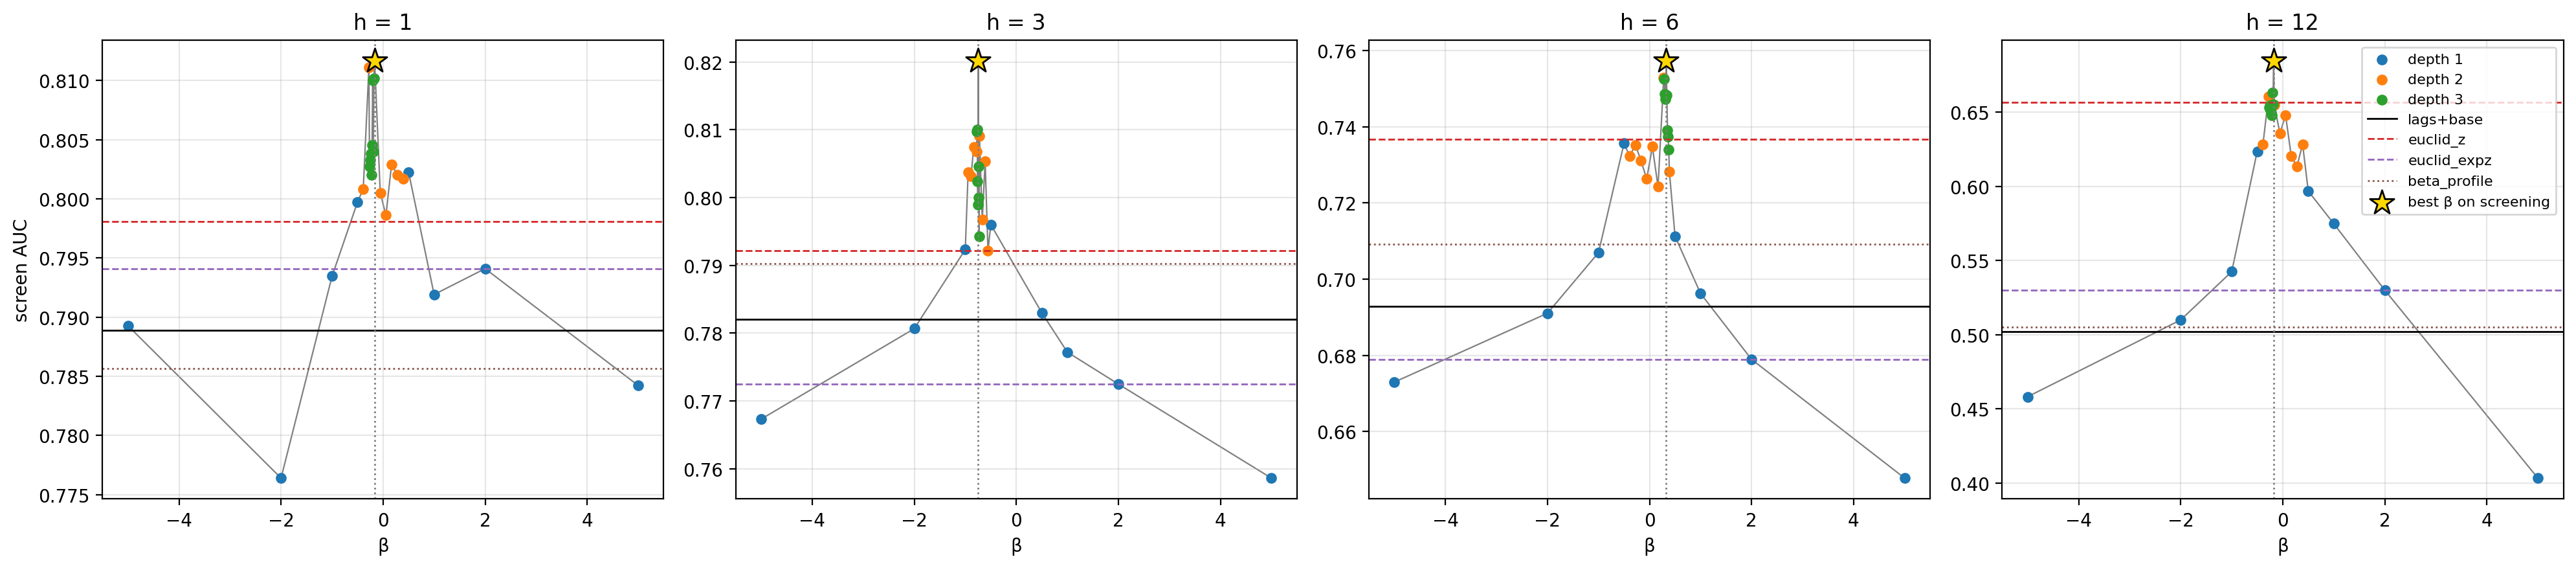

,best β,best β AUC,lags+base AUC,euclid_z AUC,euclid_expz AUC,beta_profile AUC
1,-0.166667,0.811661,0.788858,0.798052,0.794092,0.785672
3,-0.746914,0.820157,0.782043,0.792144,0.772480,0.790258
6,0.327160,0.757336,0.692924,0.736804,0.678923,0.709161
12,-0.179012,0.684522,0.502223,0.656428,0.529961,0.505112


In [17]:
DEPTH_COLORS = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}
REF_STYLES = {"lags+base": ("black", "-"), "euclid_z": ("tab:red", "--"),
              "euclid_expz": ("tab:purple", "--"), "beta_profile": ("tab:brown", ":")}


def best_beta(h):
    return max(tried[h], key=lambda b: (results["screen", b, h][0]["auc"], -b))


def curve(period, base_interval):
    rows = []
    for h in HORIZONS:
        y = targets[h]
        expz = results[period, "euclid_expz", h][1]
        base_scores, base = results[period, "lags+base", h]
        for b, depth in sorted(tried[h].items()):
            scores, pred = results[period, b, h]
            gain, lo, hi = auc_gain(pred, expz, y)
            row = {"h": h, "beta": b, "depth": depth, "auc": scores["auc"], "acc": scores["acc"],
                   "gain_vs_expz": gain, "lo": lo, "hi": hi}
            if base_interval:
                row["gain_vs_base"], row["base_lo"], row["base_hi"] = auc_gain(pred, base, y)
            else:
                row["gain_vs_base"] = scores["auc"] - base_scores["auc"]
            rows.append(row)
    return pd.DataFrame(rows)


def plot_curve(df, period):
    fig, axes = plt.subplots(1, len(HORIZONS), figsize=(5 * len(HORIZONS), 4.5))
    for ax, h in zip(axes, HORIZONS):
        d = df[df.h == h].sort_values("beta")
        ax.plot(d.beta, d.auc, color="grey", lw=0.8, zorder=1)
        for depth, g in d.groupby("depth"):
            ax.scatter(g.beta, g.auc, color=DEPTH_COLORS[depth], s=25, zorder=2, label=f"depth {depth}")
        for name, (color, ls) in REF_STYLES.items():
            ax.axhline(results[period, name, h][0]["auc"], color=color, ls=ls, lw=1, label=name)
        b = best_beta(h)
        ax.axvline(b, color="grey", ls=":", lw=1)
        ax.scatter([b], [results[period, b, h][0]["auc"]], marker="*", s=200, color="gold", edgecolor="black",
                   zorder=3, label="best β on screening")
        ax.set_title(f"h = {h}")
        ax.set_xlabel("β")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(f"{period} AUC")
    axes[-1].legend(fontsize=8, loc="best")
    fig.tight_layout()
    plt.show()


screen_curve = curve("screen", base_interval=False)
plot_curve(screen_curve, "screen")
pd.DataFrame({h: {"best β": best_beta(h), "best β AUC": results["screen", best_beta(h), h][0]["auc"],
                  **{f"{name} AUC": results["screen", name, h][0]["auc"] for name in REFERENCE_MODELS}}
              for h in HORIZONS}).T

## 10. Final test on 2000–2026

Run once. Do not use this section to choose β.

final test in 719 s


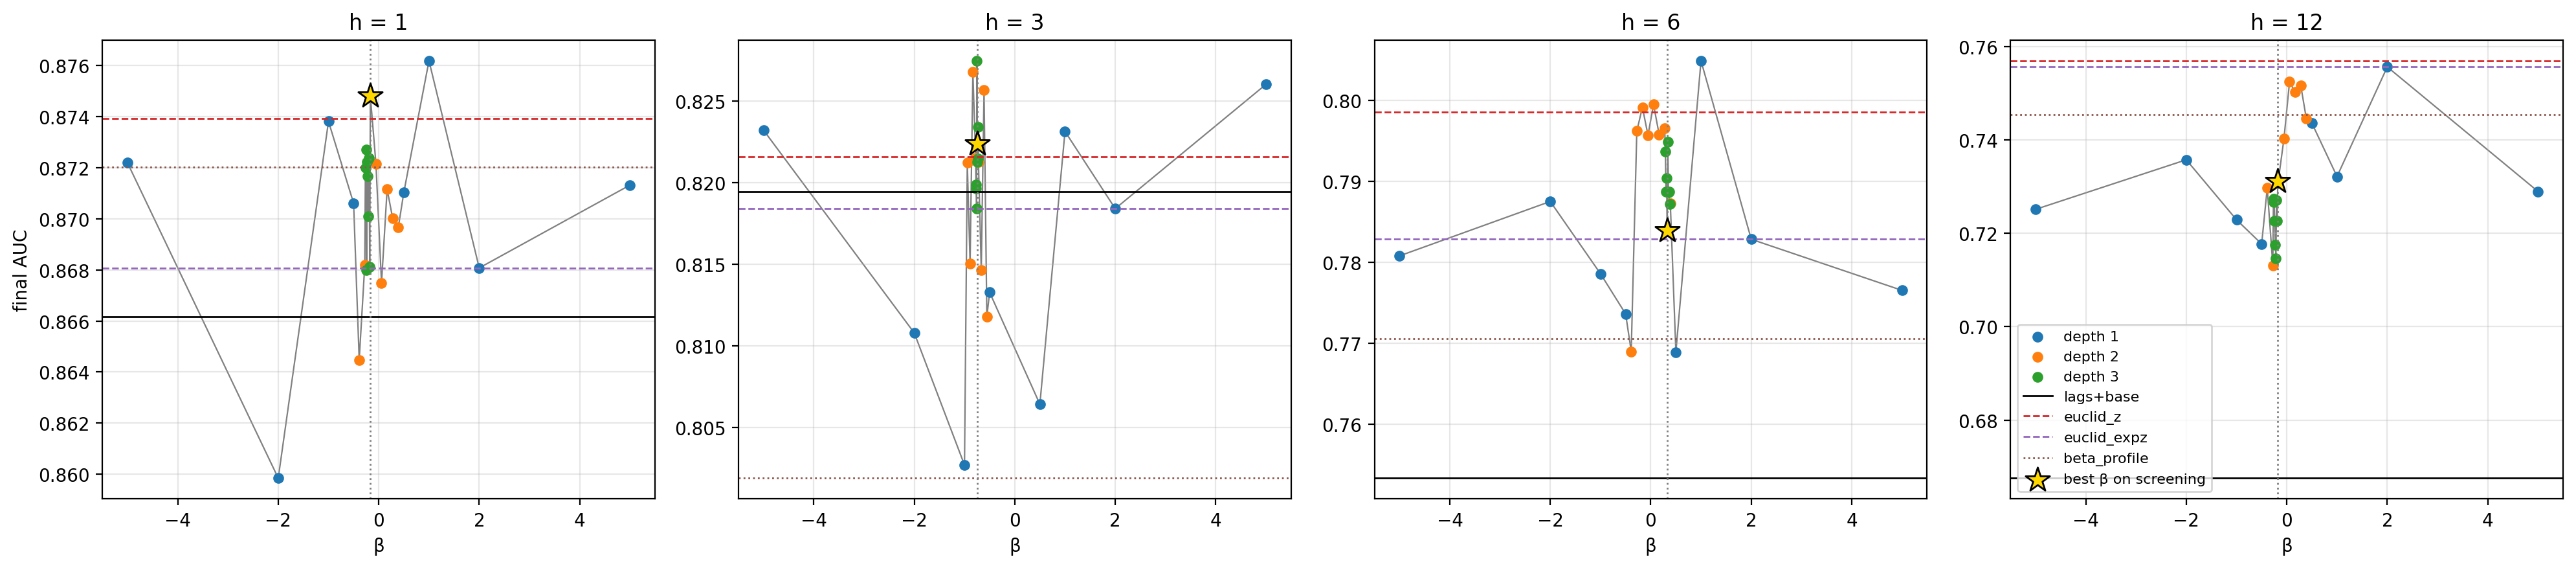

,best_beta,screen_auc,final_auc,final_gain_vs_expz,expz_lo,expz_hi,final_gain_vs_base,base_lo,base_hi,lags+base_final,euclid_z_final,euclid_expz_final,beta_profile_final,final_rank_of_best,n_tried
h,,,,,,,,,,,,,,,
1,-0.166667,0.811661,0.874802,0.006727,-0.004287,0.019086,0.008626,-0.007872,0.024080,0.866176,0.873932,0.868075,0.872032,2,24
3,-0.746914,0.820157,0.822377,0.003966,-0.010407,0.018697,0.002924,-0.026580,0.030946,0.819453,0.821576,0.818411,0.801907,8,24
6,0.327160,0.757336,0.783898,0.001066,-0.039762,0.033059,0.030596,-0.054334,0.110823,0.753302,0.798581,0.782832,0.770527,17,24
12,-0.179012,0.684522,0.731225,-0.024457,-0.062499,0.012238,0.063673,-0.034778,0.172145,0.667552,0.756989,0.755682,0.745435,11,24


In [18]:
t0 = time.perf_counter()
fit_all(REFERENCE_MODELS, "final")
for h in HORIZONS:
    fit_all(list(tried[h]), "final", horizons=[h])
final_curve = curve("final", base_interval=True).merge(
    screen_curve[["h", "beta", "auc"]].rename(columns={"auc": "screen_auc"}), on=["h", "beta"])
print(f"final test in {time.perf_counter() - t0:.0f} s")
plot_curve(final_curve, "final")

rows = []
for h in HORIZONS:
    b = best_beta(h)
    r = final_curve[(final_curve.h == h) & (final_curve.beta == b)].iloc[0]
    ranks = final_curve[final_curve.h == h].set_index("beta").auc.rank(ascending=False, method="min")
    rows.append({"h": h, "best_beta": b, "screen_auc": r.screen_auc, "final_auc": r.auc,
                 "final_gain_vs_expz": r.gain_vs_expz, "expz_lo": r.lo, "expz_hi": r.hi,
                 "final_gain_vs_base": r.gain_vs_base, "base_lo": r.base_lo, "base_hi": r.base_hi,
                 **{f"{name}_final": results["final", name, h][0]["auc"] for name in REFERENCE_MODELS},
                 "final_rank_of_best": int(ranks[b]), "n_tried": len(ranks)})
beta_summary = pd.DataFrame(rows).set_index("h")
beta_summary